In [5]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [ ]:
import json
import sys
import time

import matplotlib.pyplot as pl
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim

from models.mlp_classifier import build_mlp_classifier, extract_features


In [7]:
DATA_DIR = PROJECT_ROOT / "data"

RESULTS_DIR = PROJECT_ROOT / "results"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
METRICS_DIR = RESULTS_DIR / "metrics"
FEATURES_DIR = RESULTS_DIR / "features"
FIGURES_DIR = RESULTS_DIR / "figures"


In [8]:
for directory in [CHECKPOINT_DIR, METRICS_DIR, FEATURES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


In [9]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "xpu")

model = build_mlp_classifier().to(DEVICE)

checkpoint_path = CHECKPOINT_DIR / "mlp_classifier_best.pth"


In [10]:
legacy_checkpoint = (
    PROJECT_ROOT / "notebooks" / "results" / "checkpoints" / "mlp_classifier_best.pth"
)

if not checkpoint_path.is_file():
    if legacy_checkpoint.is_file():
        raise FileNotFoundError(
            f"Checkpoint still exists in old location:\n"
            f"{legacy_checkpoint}\n\n"
            f"Move it to:\n{checkpoint_path}"
        )

    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)

model.load_state_dict(checkpoint)
model.eval()

print("\nMLP Classifier loaded successfully!")
print(f"Device     : {DEVICE}")
print(f"Checkpoint : {checkpoint_path}")



MLP Classifier loaded successfully!
Device     : xpu
Checkpoint : D:\Main\sem5\deep-learning\ASG_2\results\checkpoints\mlp_classifier_best.pth


In [11]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

print("Number of classes:", len(CLASS_NAMES))


Number of classes: 10


In [12]:
# Extract trained weights
W1 = model[1].weight
W2 = model[3].weight
W3 = model[5].weight

print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)


W1: torch.Size([256, 784])
W2: torch.Size([64, 256])
W3: torch.Size([10, 64])


In [13]:
# Generate onehot vectors
class_ids = torch.arange(10, device=DEVICE)

y = F.one_hot(class_ids, num_classes=10).float()

# Top-down weight transposition
with torch.inference_mode():
    # Class space -> latent space
    z_hat = F.relu(y @ W3)

    # Latent space -> hidden representation
    h1_hat = F.relu(z_hat @ W2)

    # Hidden representation -> pixel space
    x_hat = torch.sigmoid(h1_hat @ W1)

    # Reshape into image dimensions
    generated_images = x_hat.reshape(-1, 1, 28, 28)

print("Generated images:", generated_images.shape)
print("Pixel range:", generated_images.min().item(), "-", generated_images.max().item())


Generated images: torch.Size([10, 1, 28, 28])
Pixel range: 0.007055715657770634 - 0.9688597917556763


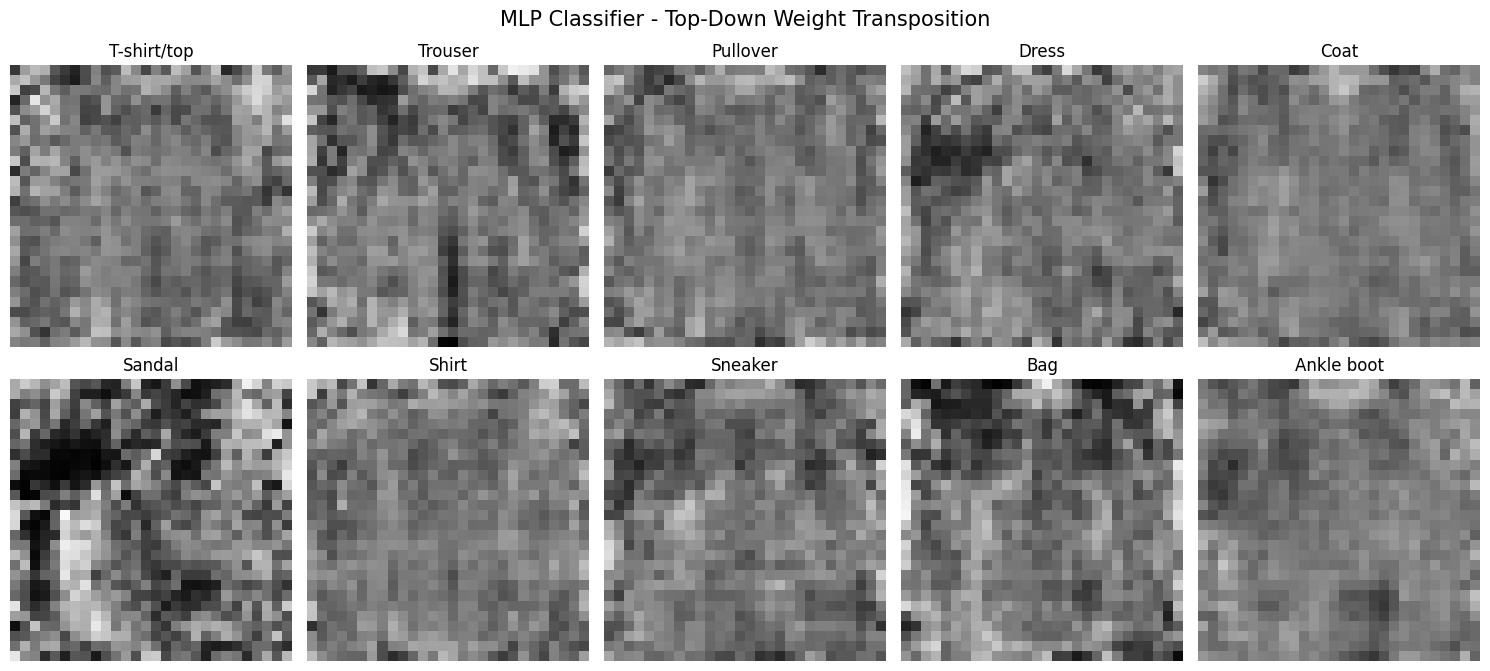

Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\exp1_weight_transposition.png


In [14]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].squeeze().cpu().numpy()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    ax.set_title(CLASS_NAMES[i])
    ax.axis("off")

fig.suptitle("MLP Classifier - Top-Down Weight Transposition", fontsize=15)

plt.tight_layout()

# Save figure before displaying
figure_path = FIGURES_DIR / "exp1_weight_transposition.png"

fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved:", figure_path)


In [15]:
# Save generated images
output_path = FEATURES_DIR / "mlp_weight_transposition.pt"

torch.save(generated_images.cpu(), output_path)

print("Generated images saved:", output_path)


Generated images saved: D:\Main\sem5\deep-learning\ASG_2\results\features\mlp_weight_transposition.pt


In [16]:
weight_matrices = {"W1": W1, "W2": W2, "W3": W3}

print("WEIGHT MATRIX ANALYSIS")

for name, weight in weight_matrices.items():
    weight = weight.detach()

    gram_matrix = weight.T @ weight

    identity = torch.eye(weight.shape[1], device=weight.device, dtype=weight.dtype)

    error = torch.linalg.norm(gram_matrix - identity, ord="fro")

    relative_error = error / torch.linalg.norm(identity, ord="fro")

    rank = torch.linalg.matrix_rank(weight)

    print(f"\n{name}")
    print("Weight shape:", tuple(weight.shape))
    print("Matrix rank:", rank.item())
    print("Relative Frobenius error:", relative_error.item())
    print("Is square:", weight.shape[0] == weight.shape[1])


WEIGHT MATRIX ANALYSIS


C:\Users\Stanislaus Alva\AppData\Local\Temp\ipykernel_17844\429653660.py:16: UserWarning: Aten Op fallback from XPU to CPU happends. This may have performance implications. If need debug the fallback ops please set environment variable `PYTORCH_DEBUG_XPU_FALLBACK=1`  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\third_party\torch-xpu-ops\src\ATen\native\xpu\XPUFallback.cpp:61.)
  rank = torch.linalg.matrix_rank(weight)



W1
Weight shape: (256, 784)
Matrix rank: 256
Relative Frobenius error: 17.169668197631836
Is square: False

W2
Weight shape: (64, 256)
Matrix rank: 64
Relative Frobenius error: 4.283871650695801
Is square: False

W3
Weight shape: (10, 64)
Matrix rank: 10
Relative Frobenius error: 1.7942103147506714
Is square: False


In [17]:
from data_loader import get_dataloaders

_, _, test_loader = get_dataloaders(root=DATA_DIR, batch_size=128, seed=42)

print("Test samples:", len(test_loader.dataset))


Test samples: 7000


In [18]:
original_images = []
latent_features = []
projected_images = []
all_labels = []

model.eval()

W1 = model[1].weight
W2 = model[3].weight

with torch.inference_mode():
    for images, labels in test_loader:
        images_device = images.to(DEVICE)

        # Extract latent features from classifier
        z = extract_features(model, images_device)

        # Transpose projection
        h1_hat = F.relu(z @ W2)
        x_hat = torch.sigmoid(h1_hat @ W1)

        # Store results
        original_images.append(images.flatten(start_dim=1))

        latent_features.append(z.cpu())
        projected_images.append(x_hat.cpu())
        all_labels.append(labels)

original_images = torch.cat(original_images)
latent_features = torch.cat(latent_features)
projected_images = torch.cat(projected_images)
all_labels = torch.cat(all_labels)

print("Original:", original_images.shape)
print("Latent:", latent_features.shape)
print("Projected:", projected_images.shape)


Original: torch.Size([7000, 784])
Latent: torch.Size([7000, 64])
Projected: torch.Size([7000, 784])


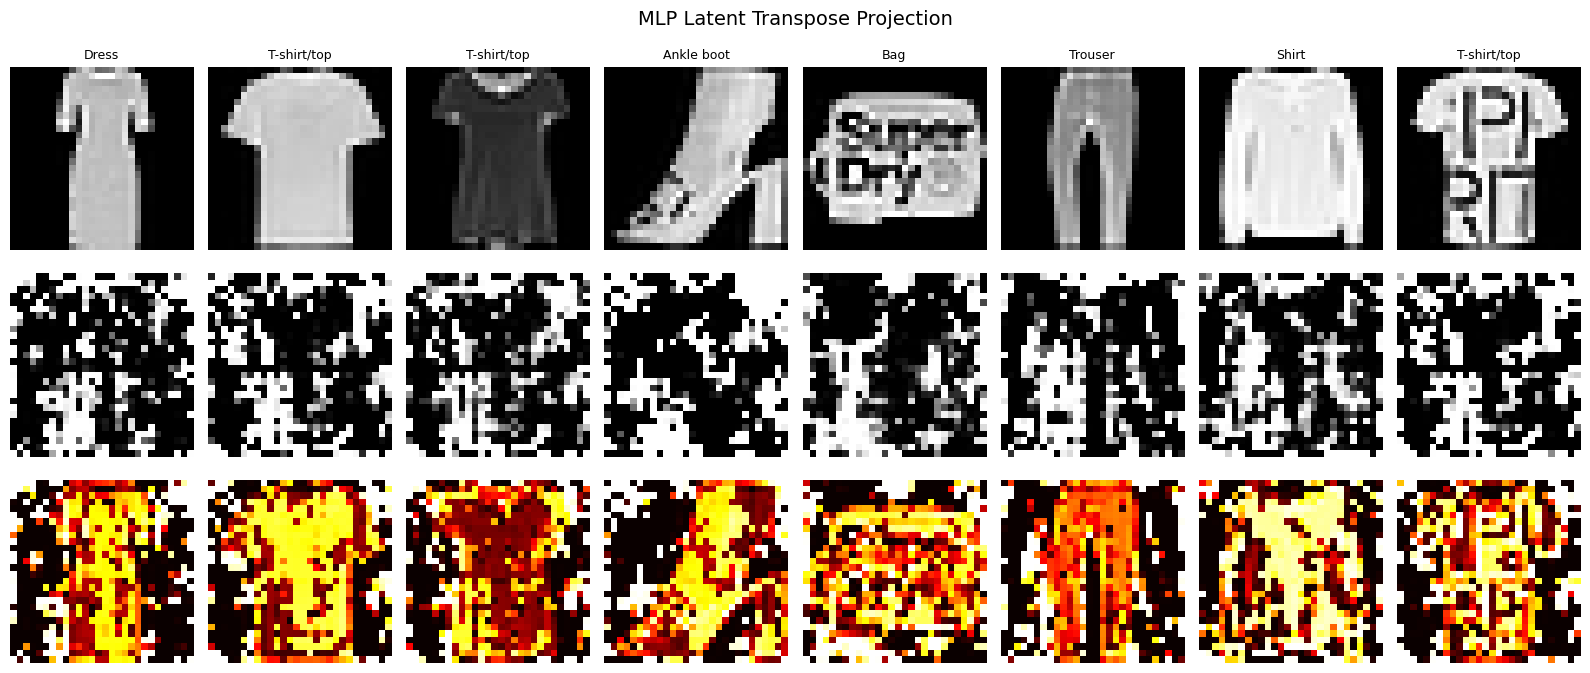

In [19]:
num_samples = 8

fig, axes = plt.subplots(3, num_samples, figsize=(16, 7))

for i in range(num_samples):
    original = original_images[i].reshape(28, 28)
    projected = projected_images[i].reshape(28, 28)

    label = all_labels[i].item()

    # Original images
    axes[0, i].imshow(original.numpy(), cmap="gray", vmin=0, vmax=1)

    axes[0, i].set_title(CLASS_NAMES[label], fontsize=9)

    axes[1, i].imshow(projected.numpy(), cmap="gray", vmin=0, vmax=1)

    difference = torch.abs(original - projected)

    axes[2, i].imshow(difference.numpy(), cmap="hot")

    axes[0, i].axis("off")
    axes[1, i].axis("off")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Projection", fontsize=10)
axes[2, 0].set_ylabel("Difference", fontsize=10)

fig.suptitle("MLP Latent Transpose Projection", fontsize=14)
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "exp2_latent_transpose_projection.png", dpi=300, bbox_inches="tight"
)

plt.show()


In [20]:
mse_per_sample = torch.mean((original_images - projected_images) ** 2, dim=1)

mean_mse = mse_per_sample.mean().item()

print("LATENT TRANSPOSE PROJECTION")
print(f"Test samples: {len(original_images)}")
print(f"Mean MSE: {mean_mse:.6f}")
print(f"Min MSE:  {mse_per_sample.min().item():.6f}")
print(f"Max MSE:  {mse_per_sample.max().item():.6f}")


LATENT TRANSPOSE PROJECTION
Test samples: 7000
Mean MSE: 0.288756
Min MSE:  0.185442
Max MSE:  0.497177


In [21]:
experiment_2_results = {
    "original_images": original_images,
    "latent_features": latent_features,
    "projected_images": projected_images,
    "labels": all_labels,
    "mse_per_sample": mse_per_sample,
    "mean_mse": mean_mse,
}

torch.save(experiment_2_results, FEATURES_DIR / "mlp_latent_transpose_projection.pt")

print("Experiment 2 artifacts saved.")


Experiment 2 artifacts saved.


In [22]:
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001


In [23]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE, seed=42)

train_eval_loader = DataLoader(
    train_loader.dataset, batch_size=BATCH_SIZE, shuffle=False
)

val_eval_loader = DataLoader(val_loader.dataset, batch_size=BATCH_SIZE, shuffle=False)

test_eval_loader = DataLoader(test_loader.dataset, batch_size=BATCH_SIZE, shuffle=False)


def extract_mlp_pairs(loader):
    model.eval()

    all_features = []
    all_images = []

    with torch.inference_mode():
        for images, _ in loader:
            images_device = images.to(DEVICE)

            # Extract 64-dimensional frozen MLP features
            z = model[:5](images_device)

            all_features.append(z.cpu())
            all_images.append(images.flatten(start_dim=1).cpu())

    return (torch.cat(all_features), torch.cat(all_images))


In [24]:
z_train, x_train = extract_mlp_pairs(train_eval_loader)
z_val, x_val = extract_mlp_pairs(val_eval_loader)
z_test, x_test = extract_mlp_pairs(test_eval_loader)

print("Training latent:", z_train.shape)
print("Training images:", x_train.shape)

print("Validation latent:", z_val.shape)
print("Test latent:", z_test.shape)


Training latent: torch.Size([56000, 64])
Training images: torch.Size([56000, 784])
Validation latent: torch.Size([7000, 64])
Test latent: torch.Size([7000, 64])


In [25]:
train_frozen_dataset = TensorDataset(z_train, x_train)
val_frozen_dataset = TensorDataset(z_val, x_val)
test_frozen_dataset = TensorDataset(z_test, x_test)

train_frozen_loader = DataLoader(
    train_frozen_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_frozen_loader = DataLoader(val_frozen_dataset, batch_size=BATCH_SIZE, shuffle=False)

test_frozen_loader = DataLoader(
    test_frozen_dataset, batch_size=BATCH_SIZE, shuffle=False
)


In [26]:
def build_decoder(latent_dim=64):
    return nn.Sequential(
        nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()
    )


frozen_decoder = build_decoder().to(DEVICE)

criterion = nn.MSELoss()

optimizer_frozen = optim.Adam(frozen_decoder.parameters(), lr=LEARNING_RATE)

print(frozen_decoder)


Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=784, bias=True)
  (3): Sigmoid()
)


In [27]:
def train_decoder_epoch(decoder, loader, optimizer):
    decoder.train()

    total_loss = 0.0
    total_samples = 0

    for z, images in loader:
        z = z.to(DEVICE)
        images = images.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        reconstruction = decoder(z)
        loss = criterion(reconstruction, images)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    return total_loss / total_samples


def evaluate_decoder(decoder, loader):
    decoder.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for z, images in loader:
            z = z.to(DEVICE)
            images = images.to(DEVICE)

            reconstruction = decoder(z)
            loss = criterion(reconstruction, images)

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    return total_loss / total_samples


In [28]:
frozen_history = []

best_frozen_val_loss = float("inf")

frozen_checkpoint_path = CHECKPOINT_DIR / "mlp_frozen_decoder_best.pth"

print("Training Frozen Latent Decoder...\n")

for epoch in range(EPOCHS):
    start_time = time.perf_counter()

    train_loss = train_decoder_epoch(
        frozen_decoder, train_frozen_loader, optimizer_frozen
    )

    val_loss = evaluate_decoder(frozen_decoder, val_frozen_loader)

    epoch_time = time.perf_counter() - start_time

    frozen_history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time": epoch_time,
        }
    )

    if val_loss < best_frozen_val_loss:
        best_frozen_val_loss = val_loss

        torch.save(frozen_decoder.state_dict(), frozen_checkpoint_path)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Train MSE: {train_loss:.6f} "
        f"| Val MSE: {val_loss:.6f} "
        f"| Time: {epoch_time:.2f}s"
    )

# Restore best decoder
frozen_decoder.load_state_dict(torch.load(frozen_checkpoint_path, map_location=DEVICE))

print("\nFrozen Decoder training completed.")


Training Frozen Latent Decoder...

Epoch [01/30] | Train MSE: 0.036446 | Val MSE: 0.027327 | Time: 5.73s
Epoch [02/30] | Train MSE: 0.025406 | Val MSE: 0.024032 | Time: 3.22s
Epoch [03/30] | Train MSE: 0.023104 | Val MSE: 0.022565 | Time: 2.73s
Epoch [04/30] | Train MSE: 0.021841 | Val MSE: 0.021583 | Time: 2.69s
Epoch [05/30] | Train MSE: 0.021058 | Val MSE: 0.020817 | Time: 2.82s
Epoch [06/30] | Train MSE: 0.020467 | Val MSE: 0.020409 | Time: 2.45s
Epoch [07/30] | Train MSE: 0.020019 | Val MSE: 0.020037 | Time: 2.41s
Epoch [08/30] | Train MSE: 0.019640 | Val MSE: 0.019777 | Time: 2.36s
Epoch [09/30] | Train MSE: 0.019329 | Val MSE: 0.019515 | Time: 2.74s
Epoch [10/30] | Train MSE: 0.019048 | Val MSE: 0.019234 | Time: 3.11s
Epoch [11/30] | Train MSE: 0.018865 | Val MSE: 0.019078 | Time: 2.85s
Epoch [12/30] | Train MSE: 0.018662 | Val MSE: 0.019016 | Time: 3.04s
Epoch [13/30] | Train MSE: 0.018473 | Val MSE: 0.018751 | Time: 3.09s
Epoch [14/30] | Train MSE: 0.018360 | Val MSE: 0.018700

In [29]:
from skimage.metrics import structural_similarity

# Load best decoder checkpoint
frozen_decoder.load_state_dict(
    torch.load(
        frozen_checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
)
frozen_decoder.eval()

reconstructed_images = []
original_test_images = []

with torch.inference_mode():
    for z, images in test_frozen_loader:
        z = z.to(DEVICE)

        reconstructions = frozen_decoder(z)

        reconstructed_images.append(reconstructions.cpu())
        original_test_images.append(images)

reconstructed_images = torch.cat(reconstructed_images)
original_test_images = torch.cat(original_test_images)

# Calculate per-image MSE
mse_per_image = torch.mean(
    (original_test_images - reconstructed_images) ** 2,
    dim=1,
)

# Calculate PSNR
psnr_per_image = 10 * torch.log10(1.0 / mse_per_image)

# Calculate SSIM
ssim_per_image = []

for original, reconstructed in zip(original_test_images, reconstructed_images):
    original_np = original.reshape(28, 28).numpy()
    reconstructed_np = reconstructed.reshape(28, 28).numpy()

    score = structural_similarity(
        original_np,
        reconstructed_np,
        data_range=1.0,
    )

    ssim_per_image.append(score)

ssim_per_image = torch.tensor(ssim_per_image)

frozen_decoder_metrics = {
    "test_mse": mse_per_image.mean().item(),
    "test_psnr": psnr_per_image.mean().item(),
    "test_ssim": ssim_per_image.mean().item(),
}

print("FROZEN DECODER TEST RESULTS")
print(f"Test samples: {len(original_test_images)}")
print(f"MSE:  {frozen_decoder_metrics['test_mse']:.6f}")
print(f"PSNR: {frozen_decoder_metrics['test_psnr']:.4f} dB")
print(f"SSIM: {frozen_decoder_metrics['test_ssim']:.4f}")


FROZEN DECODER TEST RESULTS
Test samples: 7000
MSE:  0.017882
PSNR: 18.2745 dB
SSIM: 0.6543


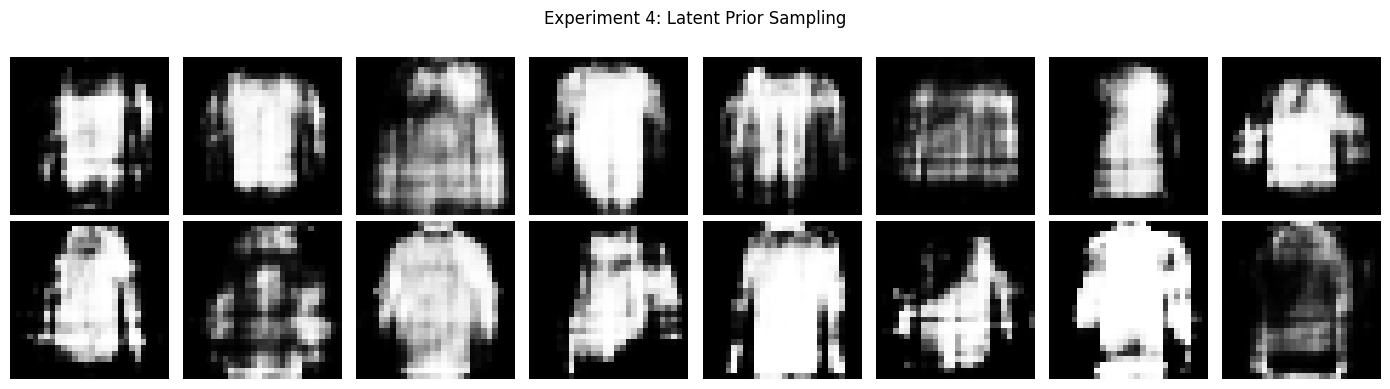

In [32]:
# Experiment 4: Latent Prior Sampling

frozen_decoder.eval()

# Estimate latent distribution from training data
latent_mean = z_train.mean(dim=0)
latent_std = z_train.std(dim=0).clamp(min=1e-6)

NUM_SAMPLES = 16

# Standard Normal prior
z_standard = torch.randn(NUM_SAMPLES, 64)

# Empirical Gaussian prior
z_empirical = torch.randn(NUM_SAMPLES, 64) * latent_std + latent_mean

with torch.inference_mode():
    standard_samples = frozen_decoder(z_standard.to(DEVICE)).cpu()

    empirical_samples = frozen_decoder(z_empirical.to(DEVICE)).cpu()

# Visualize both sampling strategies
fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i in range(NUM_SAMPLES):
    axes[0, i % 8].imshow(standard_samples[i].reshape(28, 28), cmap="gray")
    axes[0, i % 8].axis("off")

    axes[1, i % 8].imshow(empirical_samples[i].reshape(28, 28), cmap="gray")
    axes[1, i % 8].axis("off")

axes[0, 0].set_ylabel("Standard\nNormal", fontsize=10)
axes[1, 0].set_ylabel("Empirical\nGaussian", fontsize=10)

plt.suptitle("Experiment 4: Latent Prior Sampling")
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "mlp_latent_prior_sampling.png", dpi=150, bbox_inches="tight")
plt.show()


In [35]:
# Save Experiment 4 results

latent_sampling_results = {
    "experiment": "Latent Prior Sampling",
    "num_samples": NUM_SAMPLES,
    "latent_dim": 64,
    "standard_normal": {
        "mean": float(z_standard.mean()),
        "std": float(z_standard.std()),
    },
    "empirical_gaussian": {
        "mean": float(latent_mean.mean()),
        "std": float(latent_std.mean()),
    },
    "figure": "mlp_latent_prior_sampling.png",
}

metrics_path = METRICS_DIR / "mlp_latent_sampling.json"

with open(metrics_path, "w") as file:
    json.dump(latent_sampling_results, file, indent=4)

print(f"Saved: {metrics_path}")


Saved: D:\Main\sem5\deep-learning\ASG_2\results\metrics\mlp_latent_sampling.json


In [36]:
# Experiment 5: Combined Analysis

# Frozen decoder training summary
best_epoch = min(frozen_history, key=lambda item: item["val_loss"])

total_training_time = sum(item["epoch_time"] for item in frozen_history)

combined_results = {
    "experiment": "MLP Classifier Limitations",
    "experiment_1": {
        "name": "Weight Matrix Transposition",
        "figure": "exp1_weight_transposition.png",
    },
    "experiment_2": {
        "name": "Latent Feature Projection",
        "figure": "exp2_latent_projection.png",
    },
    "experiment_3": {
        "name": "Frozen Decoder Reconstruction",
        "best_epoch": best_epoch["epoch"],
        "best_validation_loss": best_epoch["val_loss"],
        "training_time_seconds": total_training_time,
        "test_metrics": frozen_decoder_metrics,
    },
    "experiment_4": latent_sampling_results,
}

# Save combined results
combined_path = METRICS_DIR / "mlp_classifier_analysis.json"

with open(combined_path, "w") as file:
    json.dump(combined_results, file, indent=4)

print("Combined MLP Analysis")
print("=" * 40)
print(f"Best decoder epoch: {best_epoch['epoch']}")
print(f"Best validation loss: {best_epoch['val_loss']:.6f}")
print(f"Training time: {total_training_time:.2f}s")
print(f"Test MSE: {frozen_decoder_metrics['test_mse']:.6f}")
print(f"Test PSNR: {frozen_decoder_metrics['test_psnr']:.4f}")
print(f"Test SSIM: {frozen_decoder_metrics['test_ssim']:.4f}")
print(f"\nSaved: {combined_path}")


Combined MLP Analysis
Best decoder epoch: 29
Best validation loss: 0.017864
Training time: 87.84s
Test MSE: 0.017882
Test PSNR: 18.2745
Test SSIM: 0.6543

Saved: D:\Main\sem5\deep-learning\ASG_2\results\metrics\mlp_classifier_analysis.json


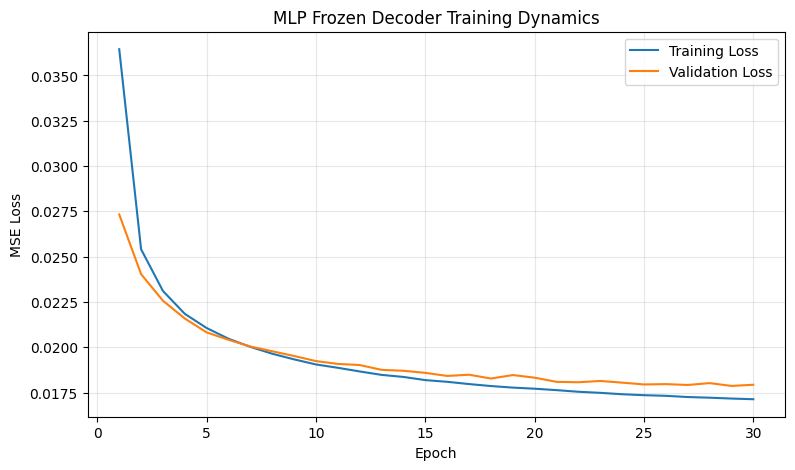

In [37]:
# Experiment 5: Frozen Decoder Training Curves

epochs_range = [item["epoch"] for item in frozen_history]

train_losses = [item["train_loss"] for item in frozen_history]

val_losses = [item["val_loss"] for item in frozen_history]

plt.figure(figsize=(9, 5))

plt.plot(epochs_range, train_losses, label="Training Loss")
plt.plot(epochs_range, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MLP Frozen Decoder Training Dynamics")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    FIGURES_DIR / "mlp_frozen_decoder_training_curves.png", dpi=150, bbox_inches="tight"
)

plt.show()
